# Analytic gradients in vacuum and constant matter

This notebook compares oscillation probabilities and their physical parameter derivatives at a baseline of 295 km and a neutrino energy of 0.6 GeV.

The default channel is **muon-neutrino to electron-neutrino appearance**, P(νμ → νe): the dimensionless probability that a neutrino produced with muon flavor is detected with electron flavor. Flavor indices are `0 = electron`, `1 = muon`, and `2 = tau`. Set `emittedFlavor, detectedFlavor = 1, 1` for muon-neutrino survival. Set `isAntiNu = True` for the corresponding antineutrino channel, then rerun setup and plotting.

The plotting cell selects `useMatter = True` for constant matter at `matterDensity = 2.6` g/cm³ and `electronFraction = 0.5`. Change it to `False` for vacuum. Density, electron fraction, baseline, and energy remain fixed while each of the six independent oscillation parameters is scanned. Layered matter profiles are not supported by this gradient API.

Each row shows the channel probability (left) and its physical derivative (right). The analytic derivative is compared with the centered finite difference `[P(p + epsilon) - P(p - epsilon)] / (2 * epsilon)`. Angles and phases are in radians; mass-squared differences are in eV². Derivatives use no weight normalization or fit-space scaling. Assertions require agreement within `rtol=2e-5, atol=2e-6`.

Jacobian columns follow `parameterBasis`, which may be a subset of the model parameters. Probabilities and gradients use the same propagation kernels and the selected `Backend` (NumPy or Torch CPU/CUDA/MPS). Model metadata is prepared on CPU; event propagation and derivatives stay on the selected device until the final NumPy results are returned. MPS uses single precision and the existing CPU fallback for eigendecomposition. In constant matter, it reuses one Hamiltonian eigendecomposition for all requested parameters and evaluates the derivative of the matrix exponential in a form that remains finite at repeated eigenvalues. Without `parameterBasis`, no gradient tensors or derivative kernels are evaluated. Use `oscillator.probability(..., parameterBasis=[parameter])` to obtain both probabilities and gradients, with the same inputs as a probability-only call. `probabilityWithGradient` remains a compatibility wrapper.

In [3]:
from pathlib import Path
import sys
import numpy as np
import matplotlib.pyplot as plt

# Allow execution from the repository root or notebooks directory.
repoRoot = Path.cwd()
if not (repoRoot / 'src').exists():
    repoRoot = repoRoot.parent
sys.path.insert(0, str(repoRoot / 'src'))

from nu_waves.models.mixing import Mixing
from nu_waves.models.spectrum import Spectrum
from nu_waves.hamiltonian import vacuum, matter
from nu_waves.propagation.oscillator import Oscillator, NeutrinoEventBatch
from nu_waves.propagation.gradient import MixingAngle, DiracPhase, MassSquaredDifference

parameterBasis = [MixingAngle(1, 2), MixingAngle(1, 3), MixingAngle(2, 3),
                  DiracPhase(1, 3), MassSquaredDifference(2, 1), MassSquaredDifference(3, 2)]
parameterNames = [r'$\theta_{12}$ [rad]', r'$\theta_{13}$ [rad]', r'$\theta_{23}$ [rad]',
                  r'$\delta_{CP}$ [rad]', r'$\Delta m^2_{21}$ [eV²]', r'$\Delta m^2_{32}$ [eV²]']
referenceValues = np.array([0.58725, 0.14819, 0.81341, -1.601, 7.53e-5, 2.509e-3])
scanWidths = [0.2, 0.07, 0.25, np.pi, 4e-5, 1e-3]
epsilons = [1e-6, 1e-6, 1e-6, 1e-6, 1e-9, 1e-9]
isAntiNu = False
emittedFlavor, detectedFlavor = 1, 0


matterDensity = 2.6  # g/cm³
electronFraction = 0.5


def makeOscillator(values, useMatter=False):
    mixing = Mixing(3, {(1, 2): values[0], (1, 3): values[1], (2, 3): values[2]},
                    {(1, 3): values[3]})
    spectrum = Spectrum(3, {(2, 1): values[4], (3, 2): values[5]})
    hamiltonian = (matter if useMatter else vacuum).Hamiltonian(mixing, spectrum, False)
    if useMatter:
        hamiltonian.set_constant_density(matterDensity, electronFraction)
    return Oscillator(hamiltonian)


events = NeutrinoEventBatch([295.], [0.6], [emittedFlavor], [detectedFlavor], [isAntiNu])
compiledEvents = makeOscillator(referenceValues).compileEvents(events)

MixingAngle(i=1, j=2): epsilon=1e-06, max absolute error=1.373e-10
MixingAngle(i=1, j=3): epsilon=1e-06, max absolute error=1.541e-10
MixingAngle(i=2, j=3): epsilon=1e-06, max absolute error=1.302e-10
DiracPhase(i=1, j=3): epsilon=1e-06, max absolute error=1.002e-10
MassSquaredDifference(i=2, j=1): epsilon=1e-09, max absolute error=1.494e-07
MassSquaredDifference(i=3, j=2): epsilon=1e-09, max absolute error=1.362e-07


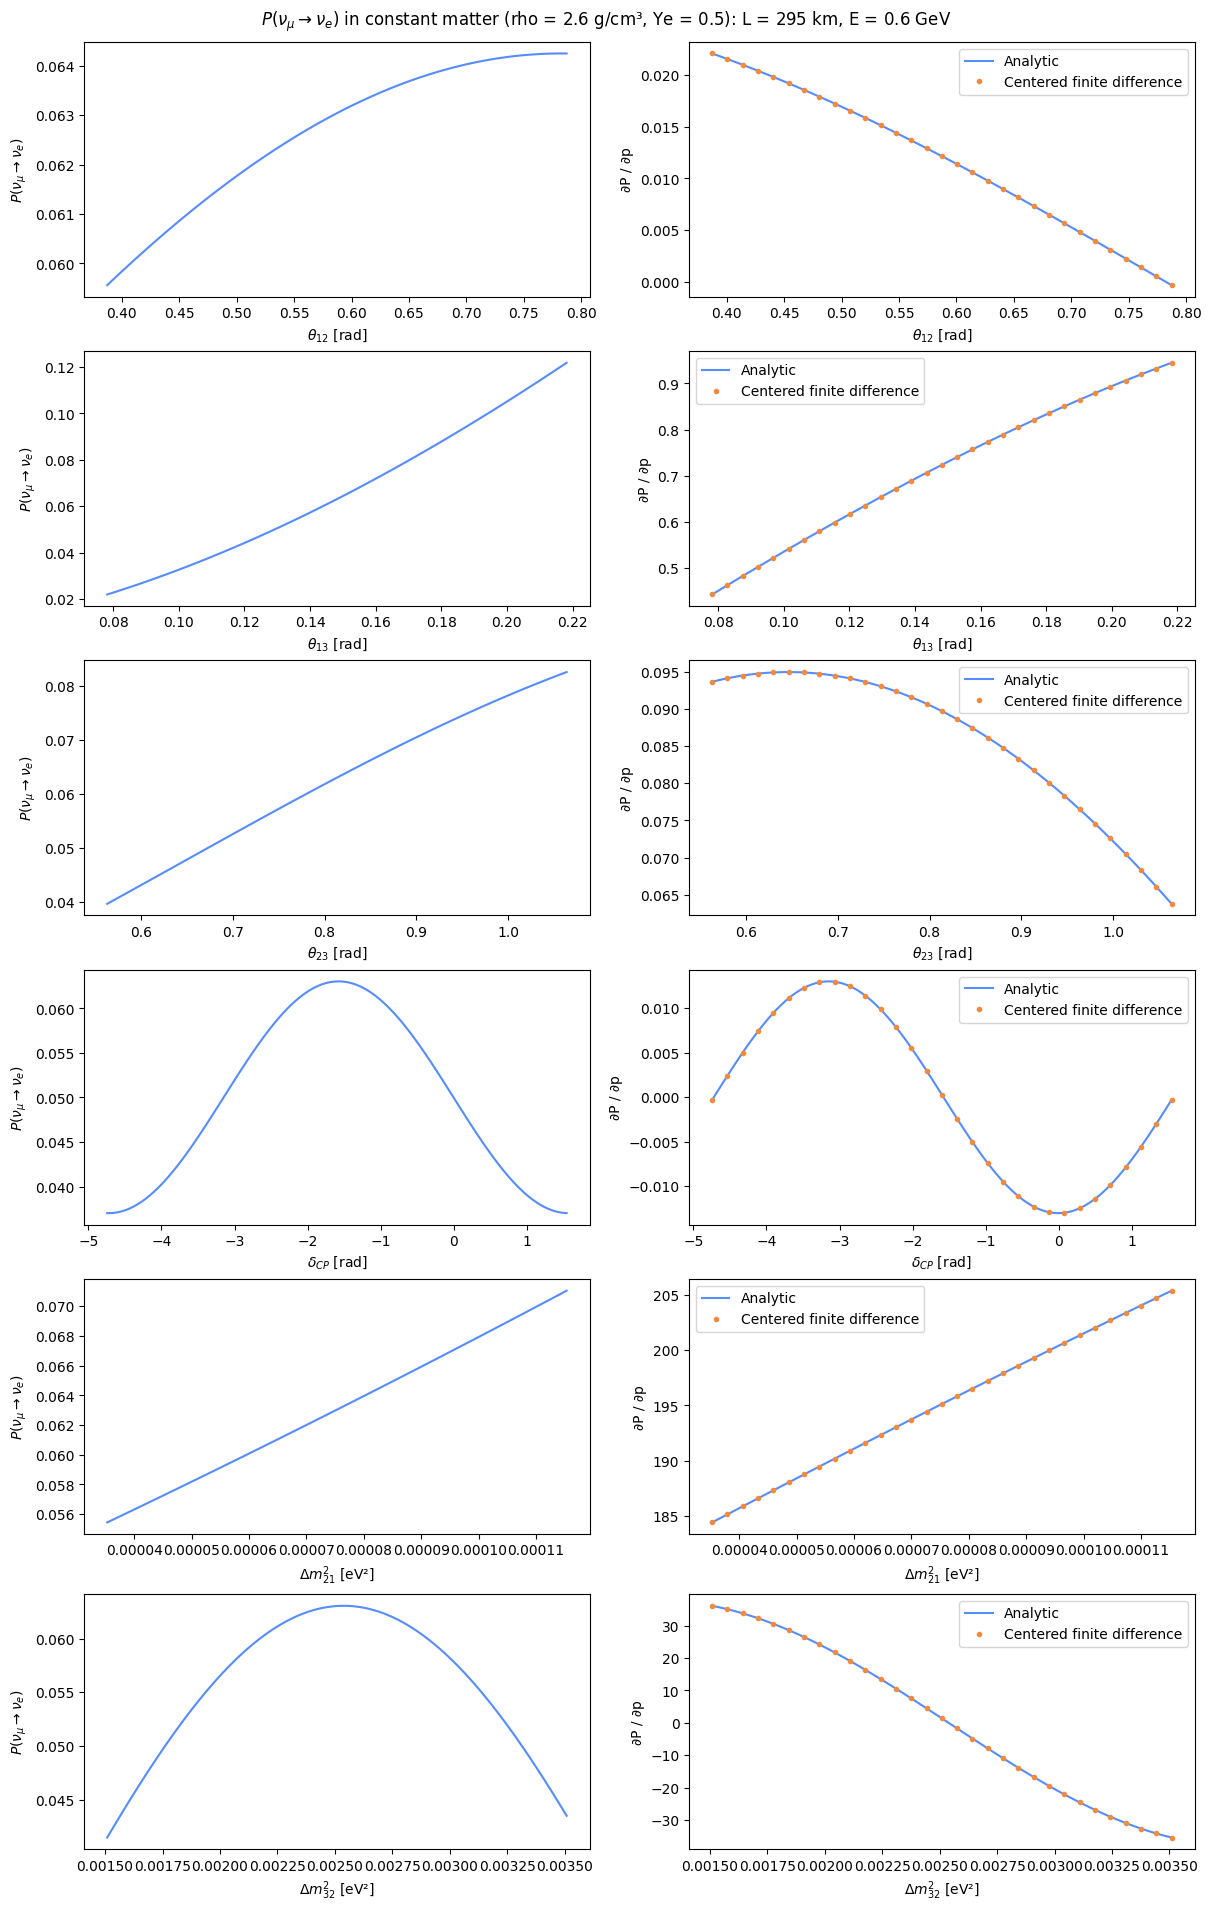

In [4]:
useMatter = True
slash = chr(92)
flavorLabels = [slash + 'nu_e', slash + 'nu_' + slash + 'mu', slash + 'nu_' + slash + 'tau']
if isAntiNu:
    flavorLabels = [slash + 'bar{' + label + '}' for label in flavorLabels]
channelLabel = flavorLabels[emittedFlavor] + ' ' + slash + 'to ' + flavorLabels[detectedFlavor]
probabilityLabel = '$P(' + channelLabel + ')$'
fig, axes = plt.subplots(6, 2, figsize=(12, 19), constrained_layout=True)
for column, (parameter, width, epsilon) in enumerate(zip(parameterBasis, scanWidths, epsilons)):
    scanValues = np.linspace(referenceValues[column] - width, referenceValues[column] + width, 121)
    probabilities, analytic, numerical = [], [], []
    for value in scanValues:
        values = referenceValues.copy()
        values[column] = value
        oscillator = makeOscillator(values, useMatter=useMatter)
        probability, gradient = oscillator.probability(compiledEvents, parameterBasis=[parameter])
        probabilities.append(probability[0])
        analytic.append(gradient[0, 0])
        plus, minus = values.copy(), values.copy()
        plus[column] += epsilon
        minus[column] -= epsilon
        numerical.append((makeOscillator(plus, useMatter=useMatter).probability(compiledEvents)[0] -
                          makeOscillator(minus, useMatter=useMatter).probability(compiledEvents)[0]) / (2 * epsilon))
    analytic, numerical = np.asarray(analytic), np.asarray(numerical)
    np.testing.assert_allclose(analytic, numerical, rtol=2e-5, atol=2e-6)
    axes[column, 0].plot(scanValues, probabilities)
    axes[column, 0].set(ylabel=probabilityLabel, xlabel=parameterNames[column])
    axes[column, 1].plot(scanValues, analytic, label='Analytic')
    axes[column, 1].plot(scanValues[::4], numerical[::4], '.', label='Centered finite difference')
    axes[column, 1].set(ylabel='∂P / ∂p', xlabel=parameterNames[column])
    axes[column, 1].legend()
    print(f'{parameter}: epsilon={epsilon:g}, max absolute error={np.max(np.abs(analytic - numerical)):.3e}')
mediumLabel = f'constant matter (rho = {matterDensity:g} g/cm³, Ye = {electronFraction:g})' if useMatter else 'vacuum'
fig.suptitle(probabilityLabel + ' in ' + mediumLabel + ': L = 295 km, E = 0.6 GeV')
plt.show()